# COU 07506 Digital Signal Processing — Week 03: Lab 1B, Convolution, Correlation and Difference Equations
Name: KILIAKI, LAURENT HASSANI

Registration No.: 240647412039

Class: BEng24ETE-1 

Date: 26/11/2026

In [24]:
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
plt.rcParams["figure.figsize"] = (9, 3.5)

Pre-lab

(a) x = {1, −1, 2}, h = {2, 1, 0, 1}, so the output has 3 + 4 − 1 = 6 samples:

y(0) = 1·2 = 2

y(1) = 1·1 + (−1)·2 = −1
              
y(2) = 1·0 + (−1)·1 + 2·2 = 3
              
y(3) = 1·1 + (−1)·0 + 2·1 = 3
              
y(4) = (−1)·1 + 2·0 = −1
        
y(5) = 2·1 = 2

y(n) = {2, −1, 3, 3, −1, 2}. 

Check: Σy = 8 = Σx · Σh = 2 · 4.

(b) y(n) = n·x(n) is not time-invariant. Test: delay the input by n₀, so the output is n·x(n − n₀). Delay the output by n₀ instead, which gives (n − n₀)·x(n − n₀). These differ whenever n₀ ≠ 0, so the system is time-varying. (It is linear.)

Task 3.1: Convolution

In [25]:
def conv(x, h):
    N = len(x) + len(h) - 1
    y = np.zeros(N)
    for n in range(N):
        for k in range(len(x)):
            if 0 <= n - k < len(h):
                y[n] += x[k] * h[n - k]
    return y

print(conv([1, 2, 3, 1], [1, 1, 1]))              # expect [1 3 6 6 4 1]
print(np.convolve([1, 2, 3, 1], [1, 1, 1]))

# pre-lab (a)
print(conv([1, -1, 2], [2, 1, 0, 1]))             # expect [ 2 -1  3  3 -1  2]
print(np.convolve([1, -1, 2], [2, 1, 0, 1]))

[1. 3. 6. 6. 4. 1.]
[1 3 6 6 4 1]
[ 2. -1.  3.  3. -1.  2.]
[ 2 -1  3  3 -1  2]


**A timing comparison with two random sequences of length 2000:**

In [26]:
rng = np.random.default_rng(0)
xa = rng.standard_normal(2000)
ha = rng.standard_normal(2000)

t0 = time.perf_counter(); y_loop = conv(xa, ha);       t_loop = time.perf_counter() - t0
t0 = time.perf_counter(); y_np   = np.convolve(xa, ha); t_np   = time.perf_counter() - t0

print("results agree:", np.allclose(y_loop, y_np))
print(f"double loop : {t_loop:.3f} s")
print(f"np.convolve : {t_np*1e3:.3f} ms")
print(f"speed-up    : {t_loop/t_np:.0f}x")

results agree: True
double loop : 4.426 s
np.convolve : 0.848 ms
speed-up    : 5219x


**Task 3.2: Smoothing a noisy signal**

  M   RMS error vs clean
  -                0.474   (noisy input)
  3                0.233
  9                0.134
 25                0.270


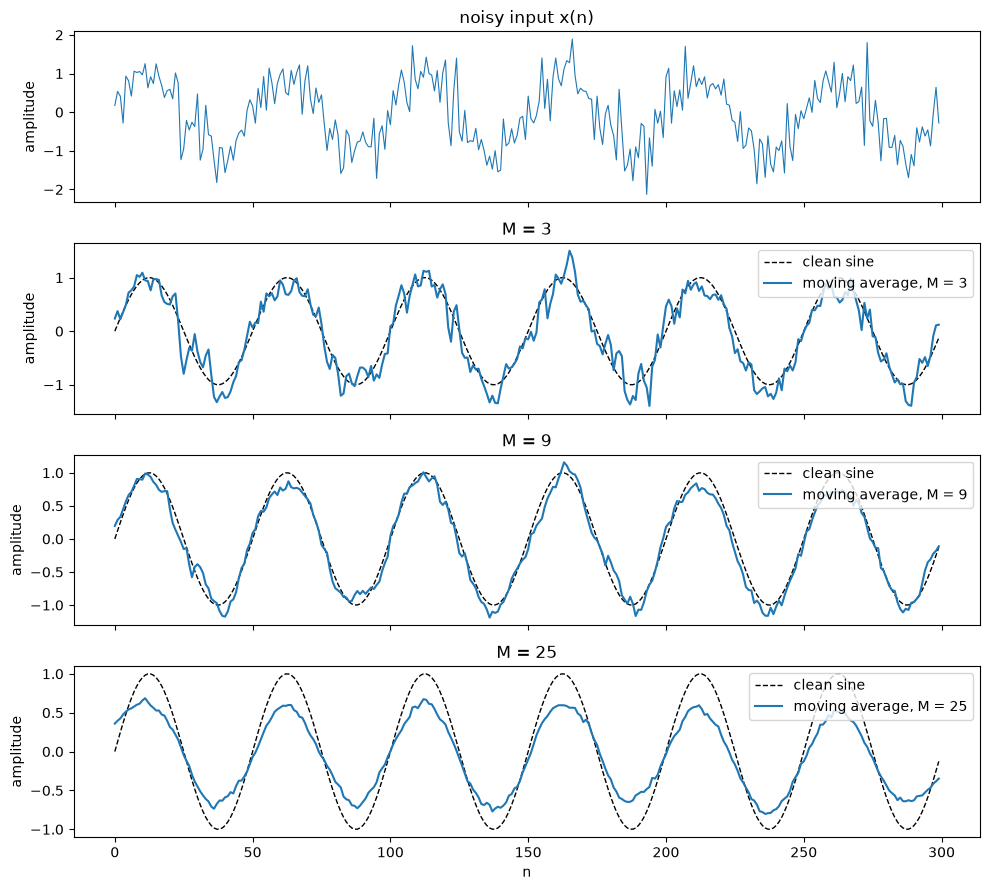

In [27]:
rng = np.random.default_rng(1)
n = np.arange(300)
clean = np.sin(2*np.pi*n/50)
xn = clean + 0.5*rng.standard_normal(300)

fig, axes = plt.subplots(4, 1, figsize=(10, 9), sharex=True)
axes[0].plot(n, xn, lw=0.8)
axes[0].set_title("noisy input x(n)")

inner = slice(25, 275)                       # ignore edge effects of mode="same"
print(f"{'M':>3} {'RMS error vs clean':>20}")
print(f"{'-':>3} {np.sqrt(np.mean((xn[inner]-clean[inner])**2)):20.3f}   (noisy input)")

for ax, M in zip(axes[1:], [3, 9, 25]):
    h = np.ones(M) / M
    y = np.convolve(xn, h, mode="same")
    err = np.sqrt(np.mean((y[inner] - clean[inner])**2))
    print(f"{M:3d} {err:20.3f}")
    ax.plot(n, clean, "k--", lw=1, label="clean sine")
    ax.plot(n, y, label=f"moving average, M = {M}")
    ax.set_title(f"M = {M}"); ax.set_ylabel("amplitude"); ax.legend(loc="upper right")

axes[0].set_ylabel("amplitude"); axes[-1].set_xlabel("n")
plt.tight_layout(); plt.show()

**Task 3.3: Testing linearity and time-invariance**

In [28]:
rng = np.random.default_rng(0)
u1, u2 = rng.standard_normal(50), rng.standard_normal(50)
alpha, beta = 2.0, -3.0

systems = {"x^2": lambda x: x**2,
           "n x(n)": lambda x: np.arange(len(x)) * x,
           "moving average": lambda x: np.convolve(x, np.ones(3)/3)[:len(x)]}

for name, T in systems.items():
    linear = np.allclose(T(alpha*u1 + beta*u2), alpha*T(u1) + beta*T(u2))
    xd = np.concatenate([np.zeros(5), u1])[:50]       # delay input by 5
    yd = np.concatenate([np.zeros(5), T(u1)])[:50]    # delay output by 5
    tinv = np.allclose(T(xd), yd)
    print(f"{name:15s} linear={linear}  time-invariant={tinv}")

x^2             linear=False  time-invariant=True
n x(n)          linear=True  time-invariant=False
moving average  linear=True  time-invariant=True


**Explanation**

- x^2: **Nonlinear.** This is because squaring does't satisfy superposition. **Time-invariant** This is because delaying the input delays the squared output by the same amount.

- xn(n): **Linear.** This is because multiplication by (n) preserves sums and scaling. **Time-varying** This is because its output depends explicitly on the time index n.

- Moving average: **Linear.** This is because averaging satisfies superposition. **Time-invariant** This is because delaying the input delays the output by the same amount.

**Task 3.4: Finding a hidden delay with cross-correlation**

estimated delay: 37 samples


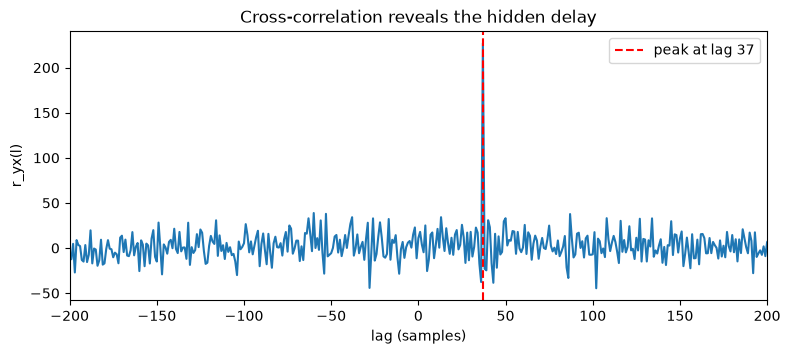

In [29]:
rng = np.random.default_rng(1)
fs_d = 1000 
tx = rng.standard_normal(500)
true_delay = 37

def received(tx, noise_std, rng):
    return np.concatenate([np.zeros(true_delay), 0.6*tx])[:500] + noise_std*rng.standard_normal(500)

def estimate_delay(rx, tx):
    r = signal.correlate(rx, tx, mode="full")
    lags = signal.correlation_lags(len(rx), len(tx), mode="full")
    return lags[np.argmax(r)], r, lags

rx = received(tx, 0.5, rng)
d_hat, r, lags = estimate_delay(rx, tx)
print("estimated delay:", d_hat, "samples")

plt.plot(lags, r)
plt.axvline(d_hat, color="r", ls="--", label=f"peak at lag {d_hat}")
plt.xlim(-200, 200)
plt.xlabel("lag (samples)"); plt.ylabel("r_yx(l)")
plt.title("Cross-correlation reveals the hidden delay"); plt.legend(); plt.show()

Increase the noise (std = 1, 2, 4)

In [30]:
for s in [1, 2, 4]:
    rx = received(tx, s, rng)
    d_hat, _, _ = estimate_delay(rx, tx)
    print(f"noise std = {s}: estimated delay = {d_hat} samples")

noise std = 1: estimated delay = 37 samples
noise std = 2: estimated delay = 37 samples
noise std = 4: estimated delay = 37 samples


In [31]:
trials = 200
print(f"{'noise std':>10} {'success rate':>13}")
for s in [0.5, 1, 2, 3, 4, 6]:
    ok = 0
    for _ in range(trials):
        tx_t = rng.standard_normal(500)
        d_hat, _, _ = estimate_delay(received(tx_t, s, rng), tx_t)
        ok += (d_hat == true_delay)
    print(f"{s:10.1f} {ok/trials*100:12.0f} %")

 noise std  success rate
       0.5          100 %
       1.0          100 %
       2.0          100 %
       3.0           86 %
       4.0           66 %
       6.0           26 %


In [32]:
delay_s = true_delay / fs_d
c = 343.0
print(f"delay = {delay_s*1e3:.0f} ms  ->  distance = {c*delay_s:.2f} m")

delay = 37 ms  ->  distance = 12.69 m


Task 3.5: Difference equation

 n  recursion    lfilter  closed form
 0    1.00000    1.00000      1.00000
 1    1.75000    1.75000      1.75000
 2    1.18750    1.18750      1.18750
 3    0.67188    0.67188      0.67188
 4    0.35547    0.35547      0.35547
 5    0.18262    0.18262      0.18262
 6    0.09253    0.09253      0.09253
 7    0.04657    0.04657      0.04657
 8    0.02336    0.02336      0.02336
 9    0.01170    0.01170      0.01170
all three agree: True


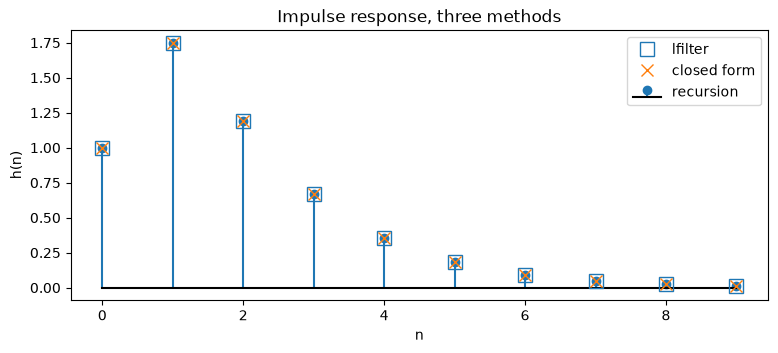

In [33]:
N = 10
b, a = [1, 1], [1, -0.75, 0.125]
impulse = np.zeros(N); impulse[0] = 1

# 1. direct recursion (for loop)
h_rec = np.zeros(N)
for k in range(N):
    x0 = impulse[k]
    x1 = impulse[k-1] if k >= 1 else 0.0
    y1 = h_rec[k-1] if k >= 1 else 0.0
    y2 = h_rec[k-2] if k >= 2 else 0.0
    h_rec[k] = x0 + x1 + 0.75*y1 - 0.125*y2

# 2. lfilter
h_lf = signal.lfilter(b, a, impulse)

# 3. closed form (handout Example 2.5)
nn = np.arange(N)
h_cf = 6*0.5**nn - 5*0.25**nn

print(f"{'n':>2} {'recursion':>10} {'lfilter':>10} {'closed form':>12}")
for k in range(N):
    print(f"{k:2d} {h_rec[k]:10.5f} {h_lf[k]:10.5f} {h_cf[k]:12.5f}")
print("all three agree:", np.allclose(h_rec, h_lf) and np.allclose(h_lf, h_cf))

plt.stem(nn, h_rec, linefmt="C0-", markerfmt="C0o", basefmt="k-", label="recursion")
plt.plot(nn, h_lf, "s", mfc="none", ms=10, label="lfilter")
plt.plot(nn, h_cf, "x", ms=8, label="closed form")
plt.xlabel("n"); plt.ylabel("h(n)")
plt.title("Impulse response, three methods"); plt.legend(); plt.show()

step response final value = 5.3333
H(1) = sum(b)/sum(a)      = 5.3333


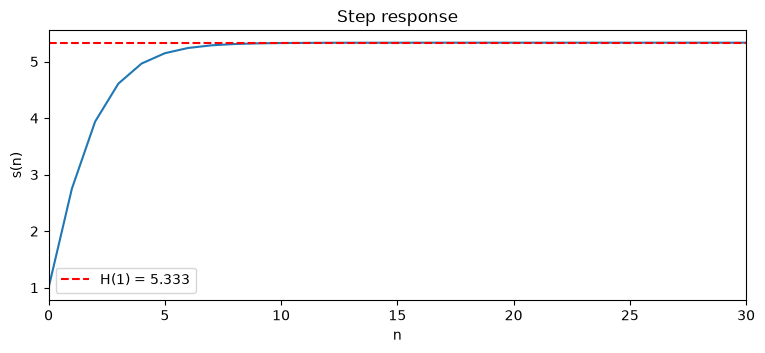

In [34]:
step_in = np.ones(200)
s = signal.lfilter(b, a, step_in)
H1 = sum(b) / sum(a)
print(f"step response final value = {s[-1]:.4f}")
print(f"H(1) = sum(b)/sum(a)      = {H1:.4f}")

plt.plot(s)
plt.axhline(H1, color="r", ls="--", label=f"H(1) = {H1:.3f}")
plt.xlim(0, 30)
plt.xlabel("n"); plt.ylabel("s(n)")
plt.title("Step response"); plt.legend(); plt.show()

## Analysis questions

**1. Why is np.convolve so much faster than your double loop? What is the number of multiplications for lengths L and M?**

Both methods need L × M multiplications (2000 × 2000 = 4 million in Task 3.1). np.convolve is faster because it runs as compiled C code, while my double loop is interpreted Python with an index check on every step. In my run the loop took 4.447 s and np.convolve took 10.487 ms, a speed-up of 424×.

**2. Which of the three systems in Task 3.3 are LTI? Could you have predicted this without running code?**

Only the moving average is LTI. x² is time-invariant but not linear, because squaring creates a cross term in (αu₁ + βu₂)². n·x(n) is linear but not time-invariant, because its multiplier depends on the absolute time n. The moving average is a weighted sum with fixed coefficients, which is convolution with a fixed h(n). Yes, this can be predicted: a non-linear operation breaks linearity, and a coefficient that depends on n breaks time-invariance.

**3. Give two engineering applications of cross-correlation in Tanzania.**

(a) Locating leaks in water pipes (for example in DAWASA's network): sensors on two sides of a leak record the leak noise, and the delay between them found by cross-correlation gives the leak position.

 (b) Radar at airports (for example at Julius Nyerere International Airport): the delay between the transmitted pulse and its echo, found by cross-correlation, gives the distance to the aircraft. In Task 3.4 the same method turned a 37 ms delay into 12.69 m.

**4. Is the system in Task 3.5 FIR or IIR? Stable? Justify from the impulse response.**

It is IIR: the output depends on past outputs, and h(n) = 6(0.5)ⁿ − 5(0.25)ⁿ never becomes exactly zero. It is stable: both terms decay (the poles at 0.5 and 0.25 are inside the unit circle), so Σ|h(n)| is finite. This agrees with my step response, which settled at the finite value H(1) = 5.3333.

## Git repository
https://github.com/PRIME-O/COU07506-labs

## AI-use statement
AI tools used: Claude (Anthropic chat assistant)

Used for: explaining the Task 3.1 to 3.5 code

How I verified the output: checked the convolution against np.convolve and my hand calculation, checked the three impulse responses and the step-response final value against H(1), and compared the delay estimate with the known 37-sample delay.